In [6]:
import hashlib
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display
from matplotlib.colors import to_rgba
from matplotlib.patches import Patch
from matplotlib.ticker import MaxNLocator

REPO = next(p for p in (Path.cwd(), *Path.cwd().parents)
            if (p / 'uni_agent').is_dir() and (p / 'meta/plot').is_dir())
PLOT = REPO / 'meta/plot'
DATASETS = {
    'SWE-bench Verified': PLOT / 'data/verified_characterization_1host_20261019.csv',
    'SWE-bench Pro': PLOT / 'data/pro_characterization_1host_spliced_20261019.csv',
}
FIGURES = PLOT / 'figure'
FIGURES.mkdir(parents=True, exist_ok=True)

sns.set_style('ticks')
sns.set_style({'font.family': ['Roboto', 'DejaVu Sans'], 'font.size': 12})
sns.set_context('paper', font_scale=2,
                rc={'lines.linewidth': 3, 'lines.markersize': 10})
plt.rcParams.update({
    'axes.spines.top': False, 'axes.spines.right': False,
    'legend.frameon': False, 'pdf.fonttype': 42, 'ps.fonttype': 42,
    'svg.fonttype': 'none',
})
PALETTE = {
    'blue_main': '#0F4D92', 'blue_secondary': '#3775BA',
    'green_3': '#8BCF8B', 'green_dark': '#397A39',
    'red_strong': '#B64342', 'neutral': '#CFCECE',
    'teal': '#42949E', 'violet': '#9A4D8E',
}


In [7]:
frames = {}
expected_usable = {
    'SWE-bench Verified': [1024, 1024, 1023, 1024],
    'SWE-bench Pro': [1024, 1020, 1020, 319],
}
for benchmark, path in DATASETS.items():
    provenance = json.loads(path.with_suffix('.provenance.json').read_text())
    assert hashlib.sha256(path.read_bytes()).hexdigest() == provenance['sha256']
    assert provenance['runtime_count'] == 1
    assert provenance['benchmark'] == {
        'SWE-bench Verified': 'swebench-verified', 'SWE-bench Pro': 'swebench-pro',
    }[benchmark]
    data = pd.read_csv(path).sort_values('concurrency_episodes').reset_index(drop=True)
    assert data.concurrency_episodes.tolist() == [64, 128, 256, 512]
    assert data.terminal_attempts.eq(1024).all()
    assert (data.verified_attempts + data.incomplete_verifications).eq(1024).all()
    assert data.usable_trajectories.tolist() == expected_usable[benchmark]
    if benchmark == 'SWE-bench Pro':
        assert data.benchmark.tolist() == ['swebench-pro-v2', 'swebench-pro',
                                           'swebench-pro', 'swebench-pro']
    data['usable_samples_per_minute'] = (
        data.usable_trajectories * 60 / data.rollout_wall_seconds
    )
    for metric in ('sandbox_cpu', 'sandbox_ram'):
        assert data[f'{metric}_mean_pct'].between(0, 100).all()
        assert data[f'{metric}_peak_5s_pct'].between(0, 100).all()
        assert (data[f'{metric}_peak_5s_pct'] >= data[f'{metric}_mean_pct']).all()
    assert data.client_active_requests_mean.ge(0).all()
    assert (data.client_active_requests_peak >= data.client_active_requests_mean).all()
    frames[benchmark] = data

summary = pd.concat({
    benchmark: data.rename(columns={
        'concurrency_episodes': 'Concurrency',
        'usable_trajectories': 'Usable samples',
        'usable_samples_per_minute': 'Usable samples / min',
        'client_active_requests_mean': 'Mean Active Requests',
        'sandbox_cpu_mean_pct': 'CPU mean (%)',
        'sandbox_cpu_peak_5s_pct': 'CPU peak ~5 s (%)',
        'sandbox_ram_mean_pct': 'Host RAM mean (%)',
        'sandbox_ram_peak_5s_pct': 'Host RAM peak ~5 s (%)',
    }).set_index('Concurrency')[[
        'Usable samples', 'Usable samples / min', 'Mean Active Requests',
        'CPU mean (%)', 'CPU peak ~5 s (%)',
        'Host RAM mean (%)', 'Host RAM peak ~5 s (%)',
    ]]
    for benchmark, data in frames.items()
}, names=['Benchmark'])
display(summary.round(2))


Usable samples  Usable samples / min  \
Benchmark          Concurrency                                         
SWE-bench Verified 64                     1024                 50.42   
                   128                    1024                 70.79   
                   256                    1023                 83.50   
                   512                    1024                 81.12   
SWE-bench Pro      64                     1024                 29.59   
                   128                    1020                 56.76   
                   256                    1020                 79.74   
                   512                     319                 24.01   

                                Mean Active Requests  CPU mean (%)  \
Benchmark          Concurrency                                       
SWE-bench Verified 64                           9.79         30.40   
                   128                         18.49         58.65   
                   256                         32.86         83.13   
                   512                         52.14         84.05   
SWE-bench Pro      64                           3.20         41.87   
                   128                          7.46         88.00   
                   256                         15.05         90.69   
                   512                        115.53         81.43   

                                CPU peak ~5 s (%)  Host RAM mean (%)  \
Benchmark          Concurrency                                         
SWE-bench Verified 64                       56.62               8.04   
                   128                      97.69              13.51   
                   256                      99.88              26.47   
                   512                      99.96              46.40   
SWE-bench Pro      64                       69.65              15.47   
                   128                      99.91              21.64   
                   256                      99.95              32.37   
                   512                      99.97              38.09   

                                Host RAM peak ~5 s (%)  
Benchmark          Concurrency                          
SWE-bench Verified 64                            12.12  
                   128                           19.80  
                   256                           39.62  
                   512                           75.37  
SWE-bench Pro      64                            26.58  
                   128                           31.04  
                   256                           48.81  
                   512                           55.93

Saved: meta/plot/figure/concurrency_characterization_1host.png, meta/plot/figure/concurrency_characterization_1host.pdf, meta/plot/figure/concurrency_characterization_1host.svg


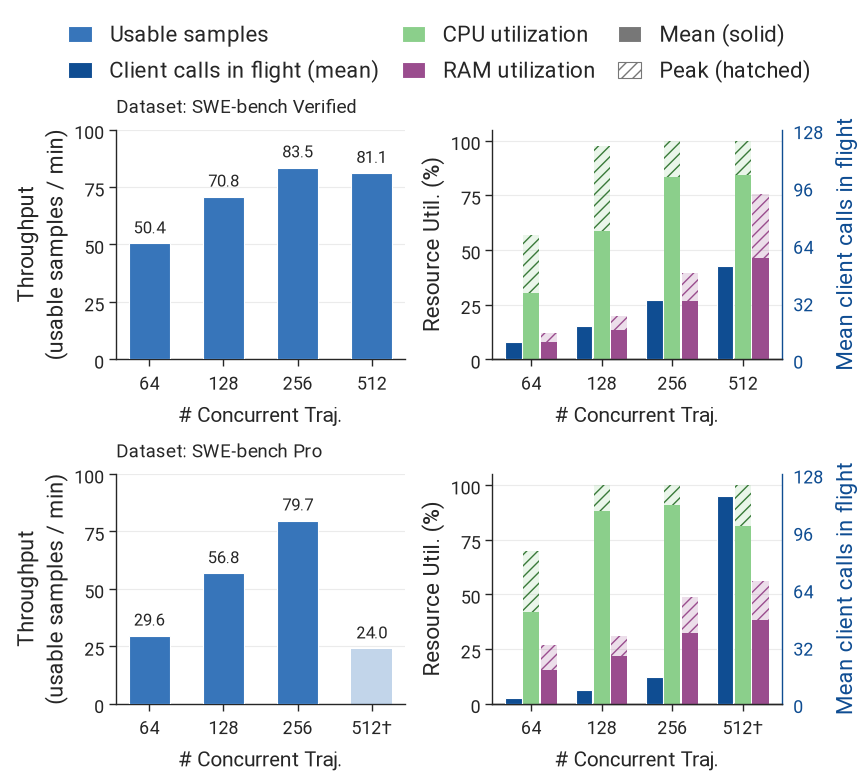

In [8]:
def mean_peak_bar(axis, positions, means, peaks, color, edgecolor=None):
    """One bar: solid base to mean, hatched extension from mean to peak."""
    edgecolor = edgecolor or color
    axis.bar(positions, means, width=.23, color=color, linewidth=0, zorder=3)
    axis.bar(positions, peaks - means, bottom=means, width=.23,
             facecolor=to_rgba(color, .18), edgecolor=edgecolor,
             hatch='///', linewidth=0, zorder=3)


def draw_characterization(datasets):
    fig, axes = plt.subplots(2, 2, figsize=(9, 8.2))
    fig.subplots_adjust(left=.14, right=.88, bottom=.13, top=.83,
                        wspace=.3, hspace=.5)
    for row, (benchmark, data) in enumerate(datasets.items()):
        throughput, resources = axes[row]
        x = np.arange(len(data))
        requests = resources.twinx()
        requests.patch.set_visible(False)
        historical = benchmark == 'SWE-bench Pro'
        labels = [str(value)  + ('†' if historical and value == 512 else '')
                  for value in data.concurrency_episodes]

        usable = throughput.bar(
            x, data.usable_samples_per_minute, width=.55,
            color=PALETTE['blue_secondary'], zorder=3)
        throughput.bar_label(
            usable, labels=[f'{value:.1f}' for value in data.usable_samples_per_minute],
            padding=4, fontsize=12)
        title = f'Dataset: {benchmark}'
        if historical:
            usable[-1].set_facecolor(to_rgba(PALETTE['blue_secondary'], .3))
            usable[-1].set_edgecolor(PALETTE['blue_secondary'])
            usable[-1].set_linewidth(0)
        throughput.set_title(title, loc='left', fontsize=13.5, pad=12)
        throughput.set_ylabel('Throughput\n(usable samples / min)', fontsize=16)
        throughput.set_ylim(0, 100)
        throughput.set_yticks([0, 25, 50, 75, 100])

        requests.bar(
            x - .25, data.client_active_requests_mean, width=.23,
            color=PALETTE['blue_main'], zorder=3)
        mean_peak_bar(resources, x, data.sandbox_cpu_mean_pct, data.sandbox_cpu_peak_5s_pct,
                      PALETTE['green_3'], PALETTE['green_dark'])
        mean_peak_bar(resources, x + .25, data.sandbox_ram_mean_pct, data.sandbox_ram_peak_5s_pct,
                      PALETTE['violet'])
        resources.set_ylabel('Resource Util. (%)', fontsize=16)
        resources.set_ylim(0, 105)
        resources.set_yticks([0, 25, 50, 75, 100])
        requests.set_ylabel('Mean client calls in flight', fontsize=16,
                            color=PALETTE['blue_main'])
        requests.set_ylim(0, 128)
        requests.set_yticks([0, 32, 64, 96, 128])
        requests.tick_params(axis='y', colors=PALETTE['blue_main'])
        requests.spines['right'].set_color(PALETTE['blue_main'])

        for axis in (throughput, resources):
            axis.set_xticks(x, labels)
            axis.set_xlabel('# Concurrent Traj.', fontsize=15)
            axis.tick_params(labelsize=13)
            axis.grid(axis='y', color=PALETTE['neutral'], linewidth=.8, alpha=.4, zorder=0)
            axis.set_axisbelow(True)
            sns.despine(ax=axis)
        requests.tick_params(labelsize=13)
        sns.despine(ax=requests, left=True, right=False)

    handles = [
        Patch(facecolor=PALETTE['blue_secondary'], label='Usable samples'),
        Patch(facecolor=PALETTE['blue_main'], label='Client calls in flight (mean)'),
        Patch(facecolor=PALETTE['green_3'], label='CPU utilization'),
        Patch(facecolor=PALETTE['violet'], label='RAM utilization'),
        Patch(facecolor='#777777', label='Mean (solid)'),
        Patch(facecolor='white', edgecolor='#777777', hatch='///', label='Peak (hatched)'),
    ]
    fig.legend(handles=handles, loc='upper center', bbox_to_anchor=(.5, .99),
               ncol=3, fontsize=16, columnspacing=1, handlelength=1.05,
               labelspacing=.3, frameon=False)
    return fig
figure = draw_characterization(frames)
output = FIGURES / 'concurrency_characterization_1host'
for extension in ('png', 'pdf', 'svg'):
    figure.savefig(output.with_suffix('.' + extension), dpi=300,
                   facecolor='white', bbox_inches='tight')
print('Saved:', ', '.join(str(output.with_suffix('.' + ext).relative_to(REPO))
                         for ext in ('png', 'pdf', 'svg')))

,benchmark,concurrent_trajectories,successful_starts,median_cold_start_s,p90_cold_start_s,median_lifetime_s
0,SWE-bench Verified,64,1024,1.83,2.31,44.00
1,SWE-bench Pro,64,1024,1.75,1.96,66.12


Saved: meta/plot/figure/episode_timelines_c64.pdf


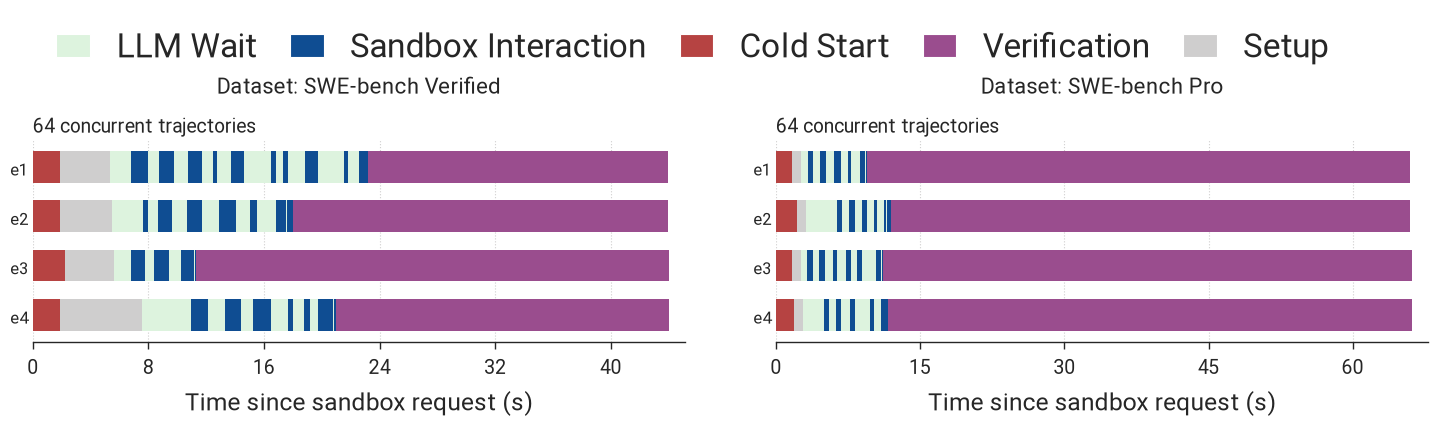

In [9]:
EPISODE_TIMELINES = {
    'SWE-bench Verified': PLOT / 'data/episode_timelines_verified_c64_20261019.json',
    'SWE-bench Pro': PLOT / 'data/episode_timelines_pro_c64_20261019.json',
}
EPISODE_COLORS = {
    'LLM Wait': '#DDF3DE', 'Cold Start': '#B64342', 'Setup': '#CFCECE',
    'Sandbox Interaction': '#0F4D92', 'Verification': '#9A4D8E',
}

episode_points, episode_rows, startup_rows = {}, [], []
for benchmark, path in EPISODE_TIMELINES.items():
    provenance = json.loads(path.with_suffix('.provenance.json').read_text())
    assert hashlib.sha256(path.read_bytes()).hexdigest() == provenance['sha256']
    data = json.loads(path.read_text())
    assert data['benchmark'] == benchmark and data['concurrency_episodes'] == 64
    characterization = json.loads(DATASETS[benchmark].with_suffix('.provenance.json').read_text())
    assert any(provenance['same_sweep_as'].split('/')[-1] in source['path']
               or data['campaign'] in source['path'] for source in characterization['sources'])
    point, = data['points']
    assert point['episode_ceiling'] == 64 and len(point['episodes']) == 4
    for episode in point['episodes']:
        assert abs(sum(episode['phase_seconds'].values()) - episode['lifetime_s']) < 1e-6
        episode_rows.append({
            'benchmark': benchmark, 'concurrent_trajectories': 64,
            'sandbox_id': episode['sandbox_id'], 'lifetime_s': episode['lifetime_s'],
            'model_calls': episode['model_calls'], 'eligible_episodes': point['eligible_episodes'],
            **episode['phase_seconds']})
    startup_rows.append({
        'benchmark': benchmark, 'concurrent_trajectories': 64,
        'successful_starts': point['successful_start_calls'],
        'median_cold_start_s': point['successful_start_median_s'],
        'p90_cold_start_s': point['successful_start_p90_s'],
        'median_lifetime_s': point['eligible_median_lifetime_s']})
    episode_points[benchmark] = point
display(pd.DataFrame(startup_rows).round(2))


def draw_c64_episode_timelines(points):
    fig, axes = plt.subplots(1, 2, figsize=(15, 4.6))
    fig.subplots_adjust(left=.06, right=.99, bottom=.24, top=.68, wspace=.14)
    for axis, (benchmark, point) in zip(axes, points.items()):
        xmax = max(e['lifetime_s'] for e in point['episodes']) * 1.025
        for index, episode in enumerate(point['episodes'], 1):
            for phase, color in EPISODE_COLORS.items():
                intervals = [(s['start_s'], s['end_s'] - s['start_s'])
                             for s in episode['segments'] if s['category'] == phase]
                if intervals:
                    axis.broken_barh(intervals, (4 - index - .32, .64),
                                     facecolors=color, edgecolors='none')
        axis.set_title('64 concurrent trajectories', loc='left', fontsize=14, pad=5)
        axis.set(xlim=(0, xmax), ylim=(-.55, 3.55), yticks=[0, 1, 2, 3],
                 yticklabels=['e4', 'e3', 'e2', 'e1'])
        axis.spines['left'].set_visible(False)
        axis.tick_params(axis='y', labelsize=12, length=0)
        axis.tick_params(axis='x', labelsize=14)
        axis.xaxis.set_major_locator(MaxNLocator(nbins=6))
        axis.set_axisbelow(True)
        axis.grid(axis='x', linestyle=':', color=PALETTE['neutral'])
        axis.set_xlabel('Time since sandbox request (s)', fontsize=17.6)
        position = axis.get_position()
        fig.text((position.x0 + position.x1) / 2, .78,
                 f'Dataset: {benchmark}', ha='center', fontsize=16)
    handles = [Patch(facecolor=color, label=phase) for phase, color in EPISODE_COLORS.items()]
    fig.legend(handles=[handles[i] for i in (0, 3, 1, 4, 2)], loc='upper center',ncol=5, frameon=False, bbox_to_anchor=(.5, 1.0), fontsize=24,
               handlelength=1.0, columnspacing=1.0, labelspacing=.45)
    return fig


episode_figure = draw_c64_episode_timelines(episode_points)
output = FIGURES / 'episode_timelines_c64'
for extension in ('png', 'pdf', 'svg'):
    episode_figure.savefig(output.with_suffix('.' + extension), dpi=300,
                           facecolor='white', bbox_inches='tight')
print('Saved:', ', '.join(str(output.with_suffix('.' + ext).relative_to(REPO))
                         for ext in ('pdf',)))

,Usable trajectories,Usable / min,Mean active requests,Peak active requests,Mean output (tokens/s),Peak output (tokens/s),Delivered output tokens,Mean resident sandbox VMs,Complete rollout minutes
CPU hosts,,,,,,,,,
1,1023,32.10,4.16,124,350.60,3557.2,670765.0,84.66,31
2,1024,42.48,6.55,127,453.34,3684.9,655987.0,74.52,23


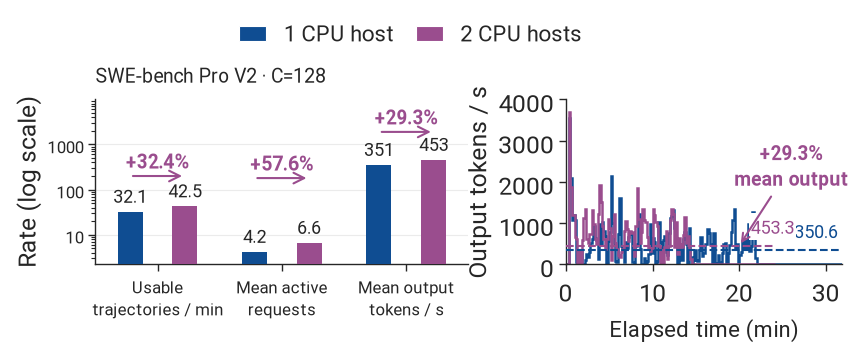

In [11]:
HOST_SCALING = PLOT / 'data/cpu_host_scaling_c128_20261019.json'
HOST_TIMELINE = PLOT / 'data/cpu_host_timeline_c128_20261019.json'
HOST_COLORS = {1: PALETTE['blue_main'], 2: PALETTE['violet']}

provenance = json.loads(HOST_SCALING.with_suffix('.provenance.json').read_text())
assert hashlib.sha256(HOST_SCALING.read_bytes()).hexdigest() == provenance['sha256']
observations = json.loads(HOST_SCALING.read_text())['rows']
runs = json.loads(HOST_TIMELINE.read_text())['runs']
assert [o['runtime_count'] for o in observations] == [r['runtime_count'] for r in runs] == [1, 2]
assert [o['usable_episodes'] for o in observations] == [1023, 1024]
host_rows = []
for observation, run in zip(observations, runs, strict=True):
    assert observation['state'] == 'completed' and observation['episode_ceiling'] == 128
    assert abs(observation['wall_seconds'] - run['duration_minutes'] * 60) < 2
    assert all(0 <= row['client_requests_mean'] <= 128 for row in run['rows'])
    assert 0 < observation['usable_episodes'] <= observation['completed_episodes']
    rows, bins = run['rows'], run['resources_1min']
    seconds = sum(row['bin_seconds'] for row in rows)
    request_mean = sum(row['client_requests_mean'] * row['bin_seconds']
                       for row in rows) / seconds
    host_rows.append({
        'CPU hosts': observation['runtime_count'],
        'Usable trajectories': observation['usable_episodes'],
        'Usable / min': observation['usable_episodes'] * 60 / observation['wall_seconds'],
        'Mean active requests': request_mean,
        'Peak active requests': max(row['client_requests_peak'] for row in rows),
        'Mean output (tokens/s)': sum(row['delivered_output_tokens_s'] * row['bin_seconds']
                                      for row in rows) / seconds,
        'Peak output (tokens/s)': max(row['delivered_output_tokens_s'] for row in rows),
        'Delivered output tokens': sum(row['delivered_output_tokens_s'] * row['bin_seconds']
                                       for row in rows),
        'Mean resident sandbox VMs': np.mean([row['sandbox_vm_count'] for row in bins]),
        'Complete rollout minutes': len(bins),
    })
host_summary = pd.DataFrame(host_rows).set_index('CPU hosts')
display(host_summary.round(2))

METRICS = [  # x tick label, mean key, value-label format
    ('Usable\ntrajectories / min', 'Usable / min', '{:.1f}'),
    ('Mean active\nrequests', 'Mean active requests', '{:.1f}'),
    ('Mean output\ntokens / s', 'Mean output (tokens/s)', '{:.0f}'),
]


def draw_cpu_host_output_tokens(host_rows, runs):
    """Mean-rate host bars (three metrics on the x-axis, one- and two-CPU-host
    bars dodged within each group; log rate axis) beside the delivered output
    tokens/s timeline (C=128).

    Notebook port of ``plot_cpu_host_throughput_requests.py --metric output-tokens``.
    """
    fig, (rates, timeline) = plt.subplots(
        1, 2, figsize=(9, 3.75), gridspec_kw={'width_ratios': (1.35, 1)})
    fig.subplots_adjust(left=.15, right=.98, bottom=.28, top=.72, wspace=.3)
    x = np.arange(len(METRICS))
    for host_index, host_count in enumerate((1, 2)):
        color = HOST_COLORS[host_count]
        positions = x + (-.22 if host_count == 1 else .22)
        for pos, (_, mean_key, fmt) in zip(positions, METRICS):
            mean = host_rows[host_index][mean_key]
            bars = rates.bar(pos, mean, width=.2, color=color, linewidth=0, zorder=3)
            rates.bar_label(bars, labels=[fmt.format(mean)], padding=3, fontsize=13)

    rates.set_yscale('log')
    rates.set(xlim=(-.5, 2.5), xticks=x, ylim=(2.2, 10000))
    rates.set_xticklabels([metric[0] for metric in METRICS], fontsize=11)
    rates.set_yticks([10, 100, 1000], labels=['10', '100', '1000'])
    for group_x, mean_key, arrow_y in ((0, 'Usable / min', 200),
                                       (1, 'Mean active requests', 180),
                                       (2, 'Mean output (tokens/s)', 1900)):
        gain = (host_rows[1][mean_key] / host_rows[0][mean_key] - 1) * 100
        rates.annotate('', xy=(group_x + .22, arrow_y),
                       xytext=(group_x - .22, arrow_y),
                       arrowprops={'arrowstyle': '->', 'color': HOST_COLORS[2],
                                   'lw': 1.5}, zorder=6)
        rates.text(group_x, arrow_y * 1.12, f'+{gain:.1f}%', ha='center', va='bottom',
                   color=HOST_COLORS[2], fontsize=14, fontweight='bold', zorder=6)
    rates.set_title('SWE-bench Pro V2 · C=128', loc='left', fontsize=14, pad=12)
    rates.set_ylabel('Rate (log scale)', fontsize=16)
    rates.tick_params(labelsize=12)
    rates.grid(axis='y', color=PALETTE['neutral'], linewidth=.8, alpha=.4, zorder=0)
    rates.set_axisbelow(True)

    lines, mean_rates = [], []
    for run in runs:
        rows = run['rows']
        edges = [0, *[(row['elapsed_minutes'] * 60 + row['bin_seconds'] / 2) / 60 for row in rows]]
        host_count = run['runtime_count']
        line = timeline.stairs([row['delivered_output_tokens_s'] for row in rows], edges,
                               baseline=None, color=HOST_COLORS[host_count], linewidth=1.8,
                               label=f"{host_count} CPU host{'s' if host_count > 1 else ''}")
        lines.append(line)
        seconds = sum(row['bin_seconds'] for row in rows)
        mean_rate = sum(row['delivered_output_tokens_s'] * row['bin_seconds']
                        for row in rows) / seconds
        mean_rates.append(mean_rate)
        timeline.hlines(mean_rate, 0, run['duration_minutes'], color=HOST_COLORS[host_count],
                        linestyle='--', linewidth=1.5, zorder=4)
        timeline.annotate(f'{mean_rate:.1f}', (run['duration_minutes'], mean_rate),
                          xytext=(14 if host_count == 2 else -3, 5), textcoords='offset points',
                          ha='right', va='bottom', color=HOST_COLORS[host_count], fontsize=13,
                          zorder=5, bbox={'facecolor': 'white', 'edgecolor': 'none', 'pad': 1})
    timeline.set(xlim=(0, max(r['duration_minutes'] for r in runs)), xticks=[0, 10, 20, 30],
                 ylim=(0, 4000), yticks=[0, 1000, 2000, 3000, 4000], ylabel='Output tokens / s')
    timeline.annotate(f'+{(mean_rates[1] / mean_rates[0] - 1) * 100:.1f}%\nmean output',
                      xy=(20, mean_rates[1]), xytext=(26, 2400), ha='center', va='center',
                      fontsize=14, color=HOST_COLORS[2], fontweight='bold',
                      arrowprops={'arrowstyle': '->', 'color': HOST_COLORS[2], 'lw': 1.5}, zorder=6)
    timeline.set_xlabel('Elapsed time (min)', fontsize=16)
    for axis in (rates, timeline):
        axis.yaxis.label.set_fontsize(17.6)
        sns.despine(ax=axis)
    fig.legend(handles=[Patch(facecolor=HOST_COLORS[1], label='1 CPU host'),
                        Patch(facecolor=HOST_COLORS[2], label='2 CPU hosts')],
               loc='upper center', bbox_to_anchor=(.5, .99), ncol=2, fontsize=16,
               columnspacing=1, handlelength=1.2, labelspacing=.3, frameon=False)
    return fig


host_figure = draw_cpu_host_output_tokens(host_rows, runs)
output = FIGURES / 'cpu_host_throughput_output_tokens_c128_pro'
for extension in ('png', 'pdf'):
    host_figure.savefig(output.with_suffix('.' + extension), dpi=300,
                        facecolor='white', bbox_inches='tight')